# 07 — Results and paired statistical uncertainty
Summarize completed experiments with a combined moving-block and predictive-draw bootstrap. Shared date paths preserve matched forecast origins, while draw-axis resampling propagates finite predictive-integration error. Simultaneous max-|z| intervals control the prespecified seven-metric family within each model contrast.

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
from innovcal.evaluation import combined_seed_draw_bootstrap, paired_draw_mc_sensitivity
FINANCIAL = ROOT / 'results' / 'financial'
OUT = ROOT / 'results' / 'uncertainty'; OUT.mkdir(parents=True, exist_ok=True)

In [2]:
archive_path = FINANCIAL / 'financial_forecasts.npz'
manifest_path = FINANCIAL / 'financial_forecast_manifest.csv'
if not archive_path.exists() or not manifest_path.exists():
    raise FileNotFoundError('Run the final forecast-export cell in notebook 06 first.')
archive = np.load(archive_path)
manifest = pd.read_csv(manifest_path)
target = archive['target']
projections = archive['projections']
if len(manifest) == 6 and 'CA-RNN (temporal penalty removed)' not in set(manifest.model):
    manifest['model'] = ['RNN', 'BRNN', 'CA-RNN (temporal penalty removed)', 'CA-BRNN (temporal penalty removed)', 'CA-RNN', 'CA-BRNN']
forecast_samples = {row.model: archive[row.array_key] for row in manifest.itertuples()}
print(f'Loaded {len(target)} matched origins, {len(forecast_samples)} models, and {len(projections)} projections.')
display(manifest)

Loaded 957 matched origins, 4 models, and 9 projections.


,model,array_key
0,RNN,samples_0
1,BRNN,samples_1
2,CA-RNN,samples_2
3,CA-BRNN,samples_3


In [3]:
COMPARISONS = [
    ('CA-RNN', 'RNN'),
    ('CA-BRNN', 'BRNN'),
]
PRIMARY_METRICS = ('mean_squared_error', 'energy_score', 'variogram_score', 'interval_score', 'coverage_error', 'pit_calibration_error', 'pit_mean_absolute_autocorrelation')
primary = combined_seed_draw_bootstrap(
    target, forecast_samples, COMPARISONS, projections,
    block_length=20, n_bootstrap=2000, n_draw_resamples=200,
    confidence=0.95, seed=707, draw_seed=1707, draw_pairing='paired',
    simultaneous_metrics=PRIMARY_METRICS, familywise_confidence=1.0 - 0.05 / len(COMPARISONS),
)
draw_mc = paired_draw_mc_sensitivity(
    target, forecast_samples, COMPARISONS, projections,
    draw_counts=(100, 250, 500), n_resamples=100, seed=1707, metrics=PRIMARY_METRICS,
)
display(primary)
primary.to_csv(OUT / 'financial_paired_block_bootstrap.csv', index=False)
draw_mc.to_csv(OUT / 'financial_draw_mc_sensitivity.csv', index=False)

,n_seeds,n_origins,block_length,n_bootstrap,candidate,comparator,metric,difference,bootstrap_se,ci_lower,...,draw_mc_variance_fraction,n_draw_resamples,draw_resampling,combined_interval_method,combined_familywise_ci_lower,combined_familywise_ci_upper,combined_familywise_critical_value,combined_familywise_family_size,combined_familywise_confidence,combined_familywise_resolved
0,1,957,20,2000,CA-RNN,RNN,mean_squared_error,0.013769,0.003487,0.007295,...,0.008092,200.0,paired,independence_convolution,0.002055,0.025482,3.348268,7.0,0.975,True
1,1,957,20,2000,CA-RNN,RNN,energy_score,0.006899,0.001993,0.002725,...,0.008113,200.0,paired,independence_convolution,0.000198,0.013601,3.348268,7.0,0.975,True
2,1,957,20,2000,CA-RNN,RNN,variogram_score,0.000155,0.000410,-0.000602,...,0.019256,200.0,paired,independence_convolution,-0.001239,0.001548,3.348268,7.0,0.975,False
3,1,957,20,2000,CA-RNN,RNN,interval_score,-0.006423,0.019773,-0.046225,...,0.040991,200.0,paired,independence_convolution,-0.073330,0.060485,3.348268,7.0,0.975,False
4,1,957,20,2000,CA-RNN,RNN,interval_width,0.093061,0.027837,0.039991,...,0.000482,200.0,paired,independence_convolution,NaN,NaN,NaN,NaN,NaN,<NA>
5,1,957,20,2000,CA-RNN,RNN,coverage,0.007576,0.002765,0.002351,...,0.324823,200.0,paired,independence_convolution,NaN,NaN,NaN,NaN,NaN,<NA>
6,1,957,20,2000,CA-RNN,RNN,coverage_error,-0.007576,0.002765,-0.013062,...,0.324869,200.0,paired,independence_convolution,-0.018900,0.003748,3.348268,7.0,0.975,False
7,1,957,20,2000,CA-RNN,RNN,pit_calibration_error,-0.000195,0.000101,-0.000446,...,0.031666,200.0,paired,independence_convolution,-0.000538,0.000147,3.348268,7.0,0.975,False
8,1,957,20,2000,CA-RNN,RNN,pit_mean_absolute_autocorrelation,0.004939,0.003292,-0.004707,...,0.015247,200.0,paired,independence_convolution,-0.006158,0.016036,3.348268,7.0,0.975,False
9,1,957,20,2000,CA-BRNN,BRNN,mean_squared_error,0.006446,0.003058,0.000490,...,0.014247,200.0,paired,independence_convolution,-0.002871,0.015762,3.016943,7.0,0.975,False


In [4]:
sensitivity = []
for block_length in [5, 20, 60]:
    sensitivity.append(combined_seed_draw_bootstrap(
        target, forecast_samples, COMPARISONS, projections,
        block_length=block_length, n_bootstrap=1000, n_draw_resamples=100, confidence=0.95,
        seed=707 + block_length, draw_seed=1707 + block_length, draw_pairing='paired',
        simultaneous_metrics=PRIMARY_METRICS, familywise_confidence=1.0 - 0.05 / len(COMPARISONS),
    ))
sensitivity = pd.concat(sensitivity, ignore_index=True)
sensitivity.to_csv(OUT / 'financial_block_length_sensitivity.csv', index=False)
display(sensitivity.query("metric in ['energy_score', 'interval_score', 'pit_calibration_error']"))

,n_seeds,n_origins,block_length,n_bootstrap,candidate,comparator,metric,difference,bootstrap_se,ci_lower,...,draw_mc_variance_fraction,n_draw_resamples,draw_resampling,combined_interval_method,combined_familywise_ci_lower,combined_familywise_ci_upper,combined_familywise_critical_value,combined_familywise_family_size,combined_familywise_confidence,combined_familywise_resolved
1,1,957,5,1000,CA-RNN,RNN,energy_score,0.006899,0.002469,0.001937,...,0.005763,100.0,paired,independence_convolution,-0.000940,0.014738,3.167784,7.0,0.975,False
3,1,957,5,1000,CA-RNN,RNN,interval_score,-0.006423,0.020831,-0.048282,...,0.052742,100.0,paired,independence_convolution,-0.073688,0.060843,3.167784,7.0,0.975,False
7,1,957,5,1000,CA-RNN,RNN,pit_calibration_error,-0.000195,0.000104,-0.000426,...,0.024542,100.0,paired,independence_convolution,-0.000531,0.000140,3.167784,7.0,0.975,False
10,1,957,5,1000,CA-BRNN,BRNN,energy_score,0.003002,0.002155,-0.001420,...,0.014908,100.0,paired,independence_convolution,-0.003211,0.009215,2.878136,7.0,0.975,False
12,1,957,5,1000,CA-BRNN,BRNN,interval_score,0.018509,0.013402,-0.006243,...,0.155162,100.0,paired,independence_convolution,-0.023542,0.060560,2.878136,7.0,0.975,False
16,1,957,5,1000,CA-BRNN,BRNN,pit_calibration_error,-0.000380,0.000130,-0.000629,...,0.033349,100.0,paired,independence_convolution,-0.000758,-0.000001,2.878136,7.0,0.975,True
19,1,957,20,1000,CA-RNN,RNN,energy_score,0.006899,0.002034,0.002457,...,0.012422,100.0,paired,independence_convolution,-0.000116,0.013915,3.405964,7.0,0.975,False
21,1,957,20,1000,CA-RNN,RNN,interval_score,-0.006423,0.019624,-0.045951,...,0.066770,100.0,paired,independence_convolution,-0.075774,0.062928,3.405964,7.0,0.975,False
25,1,957,20,1000,CA-RNN,RNN,pit_calibration_error,-0.000195,0.000099,-0.000452,...,0.035212,100.0,paired,independence_convolution,-0.000539,0.000148,3.405964,7.0,0.975,False
28,1,957,20,1000,CA-BRNN,BRNN,energy_score,0.003002,0.002052,-0.001128,...,0.017084,100.0,paired,independence_convolution,-0.003186,0.009190,2.991033,7.0,0.975,False


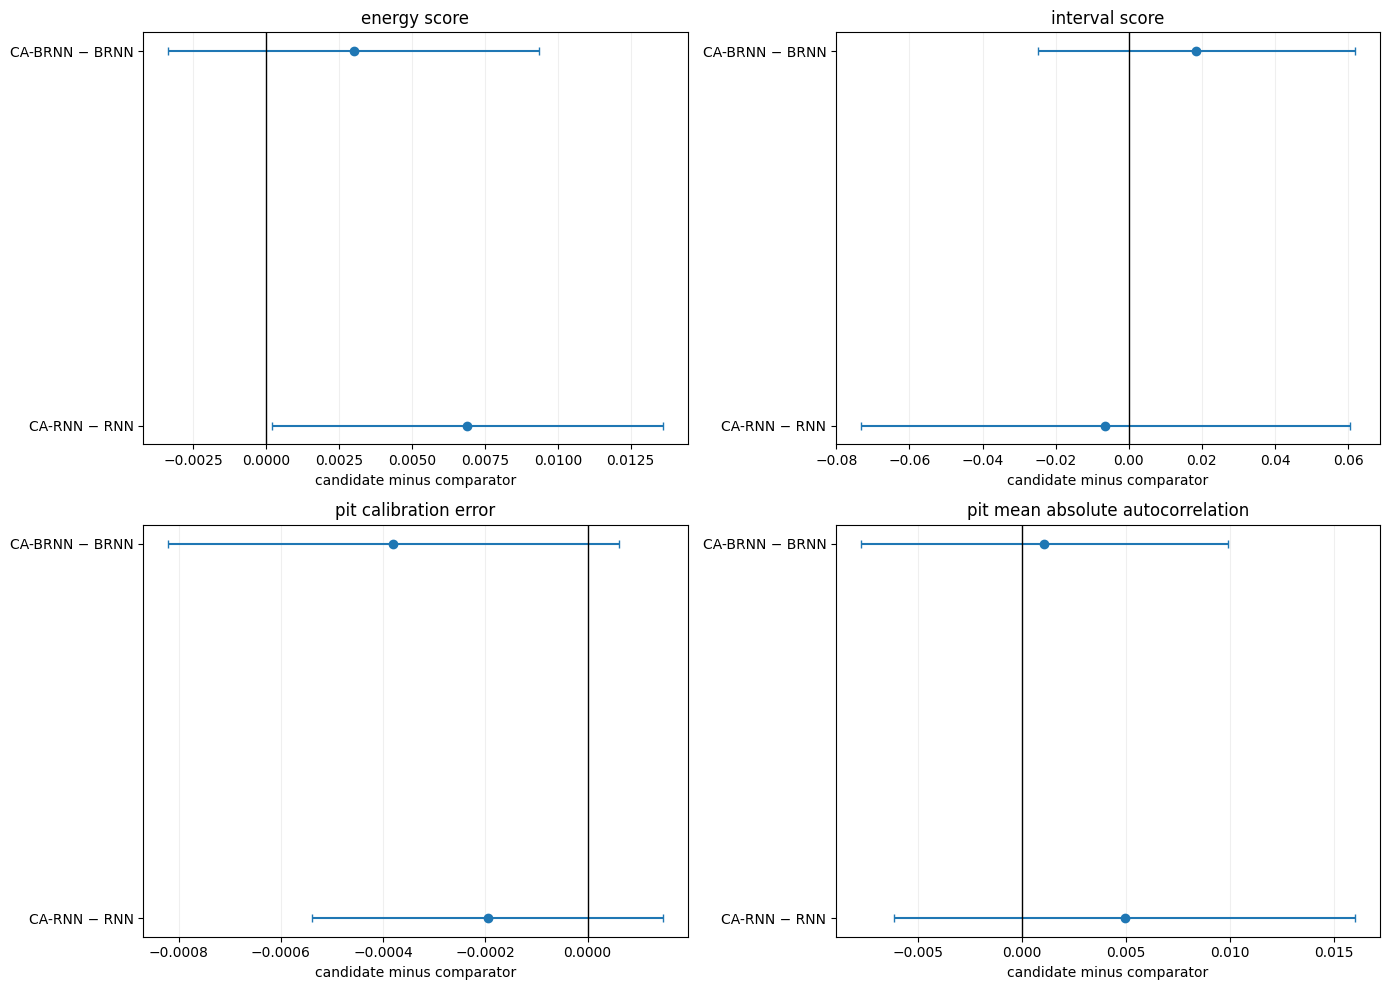

In [5]:
plot_metrics = ['energy_score', 'interval_score', 'pit_calibration_error', 'pit_mean_absolute_autocorrelation']
figure_data = primary.loc[primary.metric.isin(plot_metrics)].copy()
figure_data['comparison'] = figure_data.candidate + ' − ' + figure_data.comparator
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, metric in zip(axes.flat, plot_metrics):
    subset = figure_data.loc[figure_data.metric.eq(metric)].reset_index(drop=True)
    lower = subset.difference - subset.combined_familywise_ci_lower
    upper = subset.combined_familywise_ci_upper - subset.difference
    axis.errorbar(subset.difference, range(len(subset)), xerr=[lower, upper], fmt='o', capsize=3)
    axis.axvline(0, color='black', linewidth=1)
    axis.set_yticks(range(len(subset)), subset.comparison)
    axis.set_title(metric.replace('_', ' '))
    axis.set_xlabel('candidate minus comparator')
    axis.grid(axis='x', alpha=0.2)
plt.tight_layout()
fig.savefig(OUT / 'financial_paired_intervals.png', dpi=180, bbox_inches='tight')

In [6]:
loss_metrics = set(PRIMARY_METRICS)
decisions = primary.assign(interval_excludes_zero=primary.combined_familywise_resolved.fillna(False))
decisions['direction'] = 'descriptive'
is_loss = decisions.metric.isin(loss_metrics)
decisions.loc[is_loss & (decisions.combined_familywise_ci_upper < 0), 'direction'] = 'candidate favored'
decisions.loc[is_loss & (decisions.combined_familywise_ci_lower > 0), 'direction'] = 'comparator favored'
decisions.loc[is_loss & ~decisions.interval_excludes_zero, 'direction'] = 'unresolved'
display(decisions[['candidate', 'comparator', 'metric', 'difference', 'combined_familywise_ci_lower', 'combined_familywise_ci_upper', 'direction']])
decisions.to_csv(OUT / 'financial_interval_decisions.csv', index=False)

,candidate,comparator,metric,difference,combined_familywise_ci_lower,combined_familywise_ci_upper,direction
0,CA-RNN,RNN,mean_squared_error,0.013769,0.002055,0.025482,comparator favored
1,CA-RNN,RNN,energy_score,0.006899,0.000198,0.013601,comparator favored
2,CA-RNN,RNN,variogram_score,0.000155,-0.001239,0.001548,unresolved
3,CA-RNN,RNN,interval_score,-0.006423,-0.073330,0.060485,unresolved
4,CA-RNN,RNN,interval_width,0.093061,NaN,NaN,descriptive
5,CA-RNN,RNN,coverage,0.007576,NaN,NaN,descriptive
6,CA-RNN,RNN,coverage_error,-0.007576,-0.018900,0.003748,unresolved
7,CA-RNN,RNN,pit_calibration_error,-0.000195,-0.000538,0.000147,unresolved
8,CA-RNN,RNN,pit_mean_absolute_autocorrelation,0.004939,-0.006158,0.016036,unresolved
9,CA-BRNN,BRNN,mean_squared_error,0.006446,-0.002871,0.015762,unresolved


## Interpretation rules
- Differences are candidate minus comparator; negative values favor the candidate for loss metrics.
- A 95% simultaneous interval containing zero is unresolved, not evidence of equality.
- Raw coverage and width are descriptive. `coverage_error` is absolute deviation from nominal 90% coverage and is a lower-is-better loss.
- PIT calibration and dependence are nonlinear statistics; their intervals are recomputed within every block resample.
- Max-|z| intervals cover seven metrics within each comparison, with a Bonferroni allocation across the frequentist and Bayesian comparisons.
- Predictive-draw resampling is propagated into the main intervals and separately checked at 100, 250, and 500 retained draws.
- Compare block lengths 5, 20, and 60. Conclusions that reverse with block length are not robust.
- This single-fit analysis remains supporting evidence; the repeated-seed financial study and crossed independent-DGP experiment provide the broader uncertainty analyses.

## Project-level checklist
- Did calibration-aware training improve calibration without unacceptable proper-score loss?
- Did the sequential penalty improve temporal calibration in simulation and finance?
- Did either benefit persist under frozen-model distribution shift?
- Are conclusions consistent between frequentist and Bayesian variants?
- Which conclusions survive block-length sensitivity?
- Are exploratory hyperparameter choices clearly separated from confirmatory results?